<a href="https://colab.research.google.com/github/Mairrch/CIAP---Sentiment-Analysis/blob/comparacion-con-transformer/03_transformer_comparacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 - Comparación con Transformer (DistilBERT)
Fine-tuning de un modelo preentrenado en inglés (**DistilBERT**) para compararlo contra el baseline TF-IDF + Regresión Logística del notebook 02. El dataset está en inglés, así que se usa un modelo en inglés. Y de la misma manera la prueba debe ser en inglés

**Antes de iniciar:** Entorno de ejecución → Cambiar tipo de entorno de ejecución → **GPU (T4)**.

### 1. Entorno en collab
Clonar el repo para que las rutas funcionen.

In [5]:
import os

REPO_URL = "https://github.com/Mairrch/CIAP---Sentiment-Analysis"
REPO_NAME = "CIAP---Sentiment-Analysis"
BRANCH = "comparacion-con-transformer"

if not os.path.exists(REPO_NAME):
    !git clone -b {BRANCH} {REPO_URL}
%cd {REPO_NAME}/notebooks
!pip install -q transformers datasets accelerate

print(os.getcwd())
print(os.listdir(".."))
print(os.listdir("../data"))

Cloning into 'CIAP---Sentiment-Analysis'...
remote: Enumerating objects: 43, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 43 (delta 11), reused 30 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (43/43), 11.84 MiB | 6.73 MiB/s, done.
Resolving deltas: 100% (11/11), done.
Updating files: 100% (12/12), done.
/content/CIAP---Sentiment-Analysis/notebooks
/content/CIAP---Sentiment-Analysis/notebooks
['.git', 'README.md', '.gitignore', 'requirements.txt', '03_transformer_comparacion.ipynb', 'data', 'notebooks', 'models']
['sentiment_data.csv', 'train.csv', 'test.csv']


In [6]:
import time
import json
import joblib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, f1_score, accuracy_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay)
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding, set_seed)

SEED = 42
set_seed(SEED)

print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Sin GPU el entrenamiento tardará muchísimo, activa la GPU en el entorno de ejecución.")

GPU disponible: True
GPU: Tesla T4


### 2. Configuración
Todo lo ajustable está aquí. Con `SAMPLE = 20000` se hace una **prueba rápida** (unos minutos) para verificar que todo corre antes de lanzar el entrenamiento completo (`SAMPLE = None`).

In [7]:
DATA_DIR = "../data"
MODELS_DIR = "../models"
RESULTS_DIR = "../results"

# Modelos en inglés sugeridos (cambiar solo esta línea para probar otro):
#   "distilbert-base-uncased"  -> rápido y liviano (por defecto)
#   "bert-base-uncased"        -> BERT original, referencia de calidad
#   "roberta-base"             -> suele rendir mejor que BERT
MODEL_NAME = "distilbert-base-uncased"
MODEL_TAG = MODEL_NAME.split("/")[-1]   # se usa para nombrar los archivos de salida
NUM_LABELS = 3
MAX_LEN = 128
EPOCHS = 3
BATCH_SIZE = 32
LR = 2e-5
SAMPLE = None   # p. ej. 20000 para prueba rápida; None = datos completos

Path(MODELS_DIR).mkdir(exist_ok=True)
Path(RESULTS_DIR).mkdir(exist_ok=True)

### 3. Carga de datos
Mismos `train.csv` y `test.csv` del baseline, para que la comparación sea justa.
Separo una **validación** (5% del train) para elegir el mejor epoch. El `test` queda intocado hasta la evaluación final.

In [8]:
train_full = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

train_full["Comment"] = train_full["Comment"].fillna("")
test["Comment"] = test["Comment"].fillna("")

if SAMPLE:
    train_full = train_full.sample(SAMPLE, random_state=SEED)
    test = test.sample(min(SAMPLE // 4, len(test)), random_state=SEED)

train, val = train_test_split(train_full, test_size=0.05, stratify=train_full["Sentiment"], random_state=SEED)

print("train:", train.shape, "| val:", val.shape, "| test:", test.shape)
print(train["Sentiment"].value_counts(normalize=True).sort_index().round(3))

train: (158418, 3) | val: (8338, 3) | test: (41690, 3)
Sentiment
0    0.228
1    0.327
2    0.445
Name: proportion, dtype: float64


### 4. Tokenización
Reviso cuántos tokens suelen tener los comentarios para justificar `MAX_LEN`.

In [9]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

muestra = train["Comment"].sample(min(5000, len(train)), random_state=SEED).tolist()
lens = [len(tokenizer.encode(t, truncation=False)) for t in muestra]
print("Percentiles de longitud (tokens):", {p: int(np.percentile(lens, p)) for p in [50, 90, 95, 99]})
print(f"% de comentarios que superan MAX_LEN={MAX_LEN}:", round(np.mean(np.array(lens) > MAX_LEN) * 100, 2))

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Percentiles de longitud (tokens): {50: 18, 90: 37, 95: 43, 99: 59}
% de comentarios que superan MAX_LEN=128: 0.2


In [10]:
def to_hf(df):
    ds = Dataset.from_dict({"text": df["Comment"].tolist(), "labels": df["Sentiment"].astype(int).tolist()})
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["text"])

train_ds, val_ds, test_ds = to_hf(train), to_hf(val), to_hf(test)
collator = DataCollatorWithPadding(tokenizer=tokenizer)   # padding dinámico: más rápido

Map:   0%|          | 0/158418 [00:00<?, ? examples/s]

Map:   0%|          | 0/8338 [00:00<?, ? examples/s]

Map:   0%|          | 0/41690 [00:00<?, ? examples/s]

### 5. Fine-tuning
La métrica para elegir el mejor epoch es **Macro F1** (la misma del baseline).

In [11]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_LABELS)
steps_per_epoch = -(-len(train_ds) // BATCH_SIZE)
warmup_steps = int(0.1 * steps_per_epoch * EPOCHS)
print(f"Pasos por epoch: {steps_per_epoch} | warmup: {warmup_steps}")

args = TrainingArguments(
    output_dir="/content/checkpoints",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    learning_rate=LR,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    fp16=torch.cuda.is_available(),
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    logging_steps=200,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

t0 = time.perf_counter()
trainer.train()
train_time = time.perf_counter() - t0
print(f"\nTiempo de entrenamiento: {train_time:.1f} s ({train_time/60:.1f} min)")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pasos por epoch: 4951 | warmup: 1485


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.397700,0.416662,0.851403,0.842089
2,0.348231,0.386598,0.865675,0.857705
3,0.293504,0.391542,0.866875,0.858863


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Tiempo de entrenamiento: 904.5 s (15.1 min)


### 6. Evaluación en test y tiempo de inferencia

In [12]:
t0 = time.perf_counter()
out = trainer.predict(test_ds)
infer_time = time.perf_counter() - t0

y_test = test["Sentiment"].astype(int).values
y_pred_tr = np.argmax(out.predictions, axis=-1)

target_names = ["negativo (0)", "neutral (1)", "positivo (2)"]
print("Reporte de Clasificación (Transformer):")
print(classification_report(y_test, y_pred_tr, target_names=target_names, digits=2))

acc_tr = accuracy_score(y_test, y_pred_tr)
f1_tr = f1_score(y_test, y_pred_tr, average="macro")
ms_tr = infer_time / len(test) * 1000
print(f"Accuracy: {acc_tr:.4f} | Macro F1: {f1_tr:.4f}")
print(f"Inferencia: {infer_time:.2f} s ({ms_tr:.4f} ms/comentario) en {'GPU' if torch.cuda.is_available() else 'CPU'}")

Reporte de Clasificación (Transformer):
              precision    recall  f1-score   support

negativo (0)       0.85      0.81      0.83      9485
 neutral (1)       0.84      0.88      0.86     13638
positivo (2)       0.90      0.89      0.90     18567

    accuracy                           0.87     41690
   macro avg       0.86      0.86      0.86     41690
weighted avg       0.87      0.87      0.87     41690

Accuracy: 0.8693 | Macro F1: 0.8618
Inferencia: 22.60 s (0.5420 ms/comentario) en GPU


### 7. Baseline sobre el mismo `test`
Cargo los artefactos del notebook 02 y los evalúo sobre **exactamente las mismas filas** de `test` (importante si usaste `SAMPLE`). Si no se pueden cargar, uso las métricas reportadas en el notebook 02.

In [13]:
baseline_ok = False
try:
    vec = joblib.load(f"{MODELS_DIR}/tfidf_vectorizer.joblib")
    lr = joblib.load(f"{MODELS_DIR}/logreg_baseline.joblib")
    t0 = time.perf_counter()
    y_pred_bl = lr.predict(vec.transform(test["Comment"]))
    infer_bl = time.perf_counter() - t0
    baseline_ok = True
    print("Baseline cargado y evaluado sobre el mismo test.")
except Exception as e:
    print("No se pudo cargar el baseline:", repr(e))
    print("Se usarán las métricas reportadas en el notebook 02 (solo comparación global).")

if baseline_ok:
    acc_bl = accuracy_score(y_test, y_pred_bl)
    f1_bl = f1_score(y_test, y_pred_bl, average="macro")
    rec_neg_bl = recall_score(y_test, y_pred_bl, labels=[0], average=None)[0]
    ms_bl = infer_bl / len(test) * 1000
else:
    acc_bl, f1_bl, rec_neg_bl, ms_bl = 0.7964, 0.7825, 0.66, 0.0706 / 41690 * 1000
    y_pred_bl = None

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfTransformer from version 1.8.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator TfidfVectorizer from version 1.8.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.8.0 when using version 1.6.1. This might lead to breaking c

Baseline cargado y evaluado sobre el mismo test.


### 8. Tabla comparativa

In [15]:
rec_neg_tr = recall_score(y_test, y_pred_tr, labels=[0], average=None)[0]

comp = pd.DataFrame({
    "Modelo": ["TF-IDF + LogReg", f"{MODEL_TAG} (fine-tuned)"],
    "Accuracy": [acc_bl, acc_tr],
    "Macro F1": [f1_bl, f1_tr],
    "Recall negativo": [rec_neg_bl, rec_neg_tr],
    "ms/comentario (inferencia)": [ms_bl, ms_tr],
}).round(4)
comp

,Modelo,Accuracy,Macro F1,Recall negativo,ms/comentario (inferencia)
0,TF-IDF + LogReg,0.7964,0.7825,0.6563,0.0202
1,distilbert-base-uncased (fine-tuned),0.8693,0.8618,0.8115,0.5420


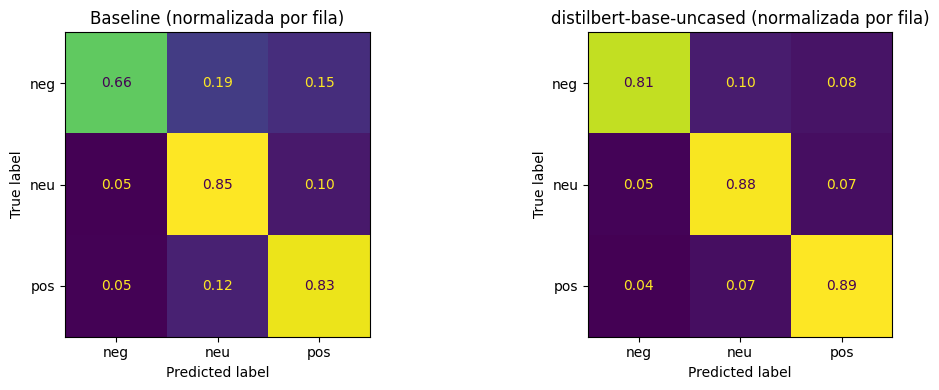

In [16]:
if y_pred_bl is not None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, yp, titulo in zip(axes, [y_pred_bl, y_pred_tr], ["Baseline", MODEL_TAG]):
        cm = confusion_matrix(y_test, yp, normalize="true")
        ConfusionMatrixDisplay(cm, display_labels=["neg", "neu", "pos"]).plot(ax=ax, colorbar=False, values_format=".2f")
        ax.set_title(f"{titulo} (normalizada por fila)")
    plt.tight_layout()
    plt.show()

### 9. Análisis de errores en negativos
¿Qué negativos se siguen escapando? ¿Cuáles corrigió el Transformer respecto al baseline? Esto alimenta el notebook 04.

In [17]:
res = test[["Comment"]].copy()
res["y_true"] = y_test
res["y_pred_transformer"] = y_pred_tr
if y_pred_bl is not None:
    res["y_pred_baseline"] = y_pred_bl

neg = res[res["y_true"] == 0]
pd.set_option("display.max_colwidth", 200)

print("== Negativos que el Transformer sigue fallando ==")
display(neg[neg["y_pred_transformer"] != 0].sample(min(15, (neg["y_pred_transformer"] != 0).sum()), random_state=SEED))

if y_pred_bl is not None:
    corregidos = neg[(neg["y_pred_baseline"] != 0) & (neg["y_pred_transformer"] == 0)]
    print(f"\n== Negativos que el baseline fallaba y el Transformer corrige ({len(corregidos)} en total) ==")
    display(corregidos.sample(min(10, len(corregidos)), random_state=SEED))

== Negativos que el Transformer sigue fallando ==


,Comment,y_true,y_pred_transformer,y_pred_baseline
36724,would great almost everything need customize first install pro cant customize font settings pro cant import old calendars pro supposed start using app,0,1,2
21780,looks like lot pink worried pms address nation forgot cant take policy decision model code conduct keep pink till may modi become,0,1,0
11477,fucking jingoist might wanted wanted man safe hands dont need boast iafs valour know theyre put forth everyone means youre national please,0,2,0
31110,effort time put relationships people learn enough trust anyone,0,1,1
28974,strange anti modi venom historian iim pass without history subject transcends even creation principle national power wow,0,2,0
12834,negotiate keep cards close chest openly attacking modi shah persona non grata lost leverage negotiate side,0,1,1
28703,india needs change modi ruined life goa petrol alcohol cheap rest everything expensive tax everything,0,2,1
35848,modi announced india âshot downâ low orbit satellite âmission shaktiâ india country ability via,0,1,0
14565,modi might hiring trolls dont know trolls setting new low everyday,0,2,0
27503,tried best write reasons modi govt failed seriously sorrybut course vote karenge,0,2,0



== Negativos que el baseline fallaba y el Transformer corrige (1811 en total) ==


,Comment,y_true,y_pred_transformer,y_pred_baseline
30345,youre fired job cant take documents premises,0,0,1
1368,rejectthese egoistic leaders mayawati rahulgandhichandershekhar ravanmamta banerji helping modi get dividing antimodi eduunempyouthscollege studentsfarmers aapcommunistbamcef bahujan workers allov...,0,0,2
32659,promises meant broken narendra modi,0,0,1
34432,modi âdivine giftâ nation says union minister harshâ vardhan,0,0,1
41625,usual hairbrained nonsense congress every election season also unfair burden maharashtra gujrath entire south india bimaru belt get tax money dont need modi supporter oppose nonsense,0,0,1
36969,modi bjp drag pakistan hindustan politics,0,0,1
9926,rather promise nyay scheme nation maybe raga pappu share secret assets grew lakhs whopping crores years fail hoga à¥à¥ à¥ à¥à¤à¥ à¤¾à¤¾à¤¤à¤¯à¤­à¤¾à¤¾à¤¿à¤°à¤à¤à¤¬à¤¾à¥à¥à¤¸à¤°à¤à¤¾,0,0,1
39871,coming back geo politics think india needs one term modi fully understand bad fundamentalist cancer wrought pakistan share poem rendition herein lies fix people,0,0,1
9731,every move modi closely watched gang left liberals ppl like pushes controversywhich rather help modi propagate matter exponentially turn helps modi increase support base,0,0,1
39945,trying finish moving stuff tonight dont feel good,0,0,2


### 10. Guardar resultados
Las predicciones y métricas son livianas y van al repo (`results/`), con el nombre del modelo en el archivo para no pisar corridas anteriores.

In [18]:
res.to_csv(f"{RESULTS_DIR}/predicciones_test_{MODEL_TAG}.csv", index=False)

metrics = {
    "modelo": MODEL_NAME, "max_len": MAX_LEN, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR,
    "n_test": int(len(test)), "accuracy": float(acc_tr), "macro_f1": float(f1_tr),
    "recall_negativo": float(rec_neg_tr), "train_time_s": float(train_time),
    "infer_ms_per_comment": float(ms_tr),
    "device_infer": "GPU" if torch.cuda.is_available() else "CPU",
}
with open(f"{RESULTS_DIR}/metricas_{MODEL_TAG}.json", "w") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print("Guardado en", RESULTS_DIR)

Guardado en ../results


### 11. Tabla consolidada de todos los modelos corridos
Aquí se juntan todos los resultados guardados en `results/`.

In [19]:
import glob
filas = []
for p in sorted(glob.glob(f"{RESULTS_DIR}/metricas_*.json")):
    with open(p) as f:
        m = json.load(f)
    filas.append({"Modelo": m["modelo"], "Accuracy": m["accuracy"], "Macro F1": m["macro_f1"],
                  "Recall negativo": m["recall_negativo"], "Entrenamiento (min)": m["train_time_s"] / 60,
                  "ms/comentario": m["infer_ms_per_comment"], "Dispositivo": m["device_infer"]})
pd.concat([pd.DataFrame([{"Modelo": "TF-IDF + LogReg (baseline)", "Accuracy": acc_bl, "Macro F1": f1_bl,
                          "Recall negativo": rec_neg_bl, "ms/comentario": ms_bl, "Dispositivo": "CPU"}]),
           pd.DataFrame(filas)], ignore_index=True).round(4)

,Modelo,Accuracy,Macro F1,Recall negativo,ms/comentario,Dispositivo,Entrenamiento (min)
0,TF-IDF + LogReg (baseline),0.7964,0.7825,0.6563,0.0202,CPU,NaN
1,distilbert-base-uncased,0.8693,0.8618,0.8115,0.5420,GPU,15.0748


### 12. Conclusiones
- **Calidad:** DistilBERT (fine-tuned) superó al baseline en todas las métricas sobre el mismo `test`: accuracy 0.80 → 0.87 y Macro F1 0.78 → 0.86. El recall de la clase negativo pasó de 0.66 a 0.81 (+15 puntos), que era el punto débil del baseline. Los negativos que se escapaban bajaron de ~34% a ~19%.
- **Costo:** el entrenamiento tomó ~15 min en GPU, frente a segundos del baseline en CPU. La inferencia es unas 27 veces más lenta por comentario (0.54 ms vs 0.02 ms), pero sigue siendo muy rápida para un uso interactivo. Los tiempos no son estrictamente comparables porque el baseline corre en CPU y DistilBERT en GPU.
- **Balance:** la mejora en negativos justifica el costo adicional en este proyecto. El baseline solo sería preferible con volúmenes enormes de datos o sin GPU.
- **Estabilidad:** entre dos corridas el recall de negativos varió ~1.4 puntos (0.83 y 0.81), un margen mucho menor que la mejora frente al baseline.
- **Errores que persisten:** en los negativos mal clasificados se repiten comentarios con hindi transliterado (el modelo es solo en inglés), críticas implícitas sin palabras negativas, sarcasmo, sentimiento mixto y etiquetas discutibles.
- **Limitaciones:** el dataset es de redes sociales y está dominado por tuits sobre política india, así que el modelo puede generalizar peor a otros dominios. Además, solo se probó un modelo (DistilBERT) con una configuración.
- **Siguiente paso:** usar `results/predicciones_test_distilbert-base-uncased.csv` para el notebook 04 de tópicos en negativos.